# 01 · Data understanding

**TalentScope notebook series** · data → EDA → preprocessing → imbalance → models → evaluation → explainability → deployment

This notebook introduces the IBM HR Analytics Employee Attrition & Performance dataset, checks that the file on disk is
the one documented, and runs the same validation pipeline the dashboard's *Data laboratory* page uses
(`talentscope.data.validate_dataset`).

> **The data is synthetic.** IBM data scientists created it to resemble an HR system. It contains no real employees,
> and patterns found in it are not evidence about any real organisation.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from talentscope import config
from talentscope.reporting import figures as F
F.setup()
print("TalentScope root:", ROOT.name, "| seed", config.RANDOM_SEED)

TalentScope root: TalentScope | seed 42


## 1. Source and version

The CSV is committed at `data/raw/ibm_hr_employee_attrition.csv`. It was taken from IBM's public
`employee-attrition-aif360` repository, which hosts the same file as the Kaggle dataset
(`pavansubhasht/ibm-hr-analytics-attrition-dataset`). The SHA-256 hash below pins the exact version every result in
this project was computed on.

In [2]:
from talentscope.data import load_raw, dataset_card, schema
raw = load_raw()
card = dataset_card(raw)
pd.Series(card).to_frame("value")

,value
name,IBM HR Analytics Employee Attrition & Performance
source_url,https://www.kaggle.com/datasets/pavansubhasht/...
mirror_url,https://raw.githubusercontent.com/IBM/employee...
license,Fictional dataset created by IBM data scientis...
synthetic,True
file,data/raw/ibm_hr_employee_attrition.csv
sha256,d11789e1db393cd1d985ca41a0e73a1d405543fb2c0d54...
rows,1470
columns,35
positives,237


## 2. Shape, columns and types

In [3]:
print("shape:", raw.shape)
raw.head()

shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [4]:
from talentscope.data.validation import column_profile
profile = column_profile(raw)
profile[["column", "role", "dtype", "unique", "missing", "min", "max", "description"]]

,column,role,dtype,unique,missing,min,max,description
0,Age,numeric,int64,43,0,18.0,60.0,Employee age in years
1,Attrition,target,object,2,0,NaN,NaN,Target: whether the employee left the company ...
2,BusinessTravel,nominal,object,3,0,NaN,NaN,Frequency of business travel
3,DailyRate,numeric,int64,886,0,102.0,1499.0,Daily pay rate (synthetic currency units)
4,Department,nominal,object,3,0,NaN,NaN,Organisational department
5,DistanceFromHome,numeric,int64,29,0,1.0,29.0,Commute distance from home to work
6,Education,ordinal,int64,5,0,1.0,5.0,"Education level, 1 (Below College) to 5 (Doctor)"
7,EducationField,nominal,object,6,0,NaN,NaN,Field of the highest qualification
8,EmployeeCount,constant (dropped),int64,1,0,1.0,1.0,"Constant column, always 1 (dropped)"
9,EmployeeNumber,identifier (dropped),int64,1470,0,1.0,2068.0,Unique employee identifier (dropped)


The 35 columns fall into six roles:

* **target**: `Attrition` (Yes / No)
* **identifier**: `EmployeeNumber`, a row ID with no predictive meaning
* **constants**: `EmployeeCount`, `Over18` and `StandardHours`, each holding a single value
* **14 numeric** attributes (age, pay rates, tenure and experience counts)
* **9 ordinal** survey and level codes (1 to 4 or 1 to 5, where order matters)
* **7 nominal** categories (department, role, travel, gender, marital status, education field, overtime)

In [5]:
profile["role"].value_counts().rename("columns").to_frame()

,columns
role,
numeric,14
ordinal,9
nominal,7
constant (dropped),3
target,1
identifier (dropped),1


## 3. Target distribution

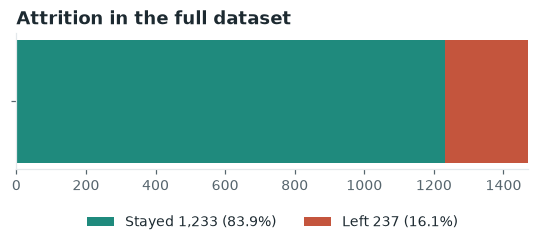

Imbalance ratio 5.20 : 1. A model that always predicts 'stay' is 83.9% accurate.


In [6]:
vc = raw["Attrition"].value_counts()
rate = vc["Yes"] / len(raw)
fig, ax = plt.subplots(figsize=(6, 1.6))
ax.barh([""], [vc["No"]], color=F.TEAL, label=f"Stayed {vc['No']:,} ({1 - rate:.1%})")
ax.barh([""], [vc["Yes"]], left=[vc["No"]], color=F.CLAY, label=f"Left {vc['Yes']:,} ({rate:.1%})")
ax.set_xlim(0, len(raw)); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2); ax.grid(False)
ax.set_title("Attrition in the full dataset"); plt.show()
print(f"Imbalance ratio {vc['No'] / vc['Yes']:.2f} : 1. A model that always predicts 'stay' is {1 - rate:.1%} accurate.")

About one employee in six left. That imbalance drives three decisions later in the series:

* Accuracy is not a useful headline metric.
* Splits must be stratified so every fold keeps the 16% rate.
* Rebalancing strategies are worth testing, though not assuming.

## 4. Data quality: the validation report

In [7]:
from talentscope.data import validate_dataset
rep = validate_dataset(raw)
print(f"{rep.n_pass} passed, {rep.n_warn} warnings, {rep.n_fail} failures")
rep.to_frame()

18 passed, 2 warnings, 0 failures


,group,name,status,detail
0,schema,Shape,pass,"1,470 rows x 35 columns (documented: 1,470 x 35)"
1,schema,Documented columns present,pass,all 35 documented columns are present
2,schema,No undocumented columns,pass,no extra columns
3,schema,Feature types,pass,"14 numeric, 9 ordinal and 7 nominal features t..."
4,quality,Missing values,pass,no missing cells in any column
5,quality,Duplicate rows,pass,0 exact duplicates; 0 duplicates once Employee...
6,quality,EmployeeNumber is unique,pass,one row per employee
7,target,Target distribution,pass,237 left (16.1%) and 1233 stayed; imbalance ra...
8,target,Target labels,pass,labels are exactly Yes / No
9,redundancy,Constant columns,pass,"EmployeeCount, Over18, StandardHours carry a s..."


**Missing values and duplicates.** There are no missing cells and no duplicate rows, including when `EmployeeNumber`
is ignored. The pipeline still contains imputers (fitted per training fold) so that it is safe on new records with gaps.

In [8]:
rep.missing.query("missing > 0") if rep.missing["missing"].sum() else "no missing values in any column"

'no missing values in any column'

**Constant and redundant columns.** Three columns carry one value for every employee. Several numeric pairs are strongly
correlated (job level and monthly income at r = 0.95). Correlated features are kept: none duplicates another, and the
models tolerate collinearity. The cost is that importance gets *shared* between them, which matters when reading SHAP
values in notebook 07.

In [9]:
print("constant columns:", rep.constant_columns)
rep.redundant_pairs

constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


,feature_a,feature_b,abs_pearson_r
0,MonthlyIncome,JobLevel,0.950
1,TotalWorkingYears,JobLevel,0.782
2,PercentSalaryHike,PerformanceRating,0.774
3,MonthlyIncome,TotalWorkingYears,0.773
4,YearsAtCompany,YearsWithCurrManager,0.769
5,YearsAtCompany,YearsInCurrentRole,0.759
6,YearsInCurrentRole,YearsWithCurrManager,0.714


**Unexpected values.** Every categorical value appears in the data dictionary, and every numeric column falls inside a
plausible range. The logical constraints hold for every employee: role tenure ≤ company tenure ≤ total experience, and
manager tenure ≤ company tenure. One weakness is that `PerformanceRating` only takes the values 3 and 4, so it can
carry little signal.

In [10]:
display(rep.unexpected_values if len(rep.unexpected_values) else "no undocumented categories")
display(rep.out_of_range if len(rep.out_of_range) else "no out-of-range values")
raw["PerformanceRating"].value_counts().sort_index().rename("employees").to_frame()

'no undocumented categories'

'no out-of-range values'

,employees
PerformanceRating,
3,1244
4,226


## 5. Leakage screen

A feature that almost perfectly separates leavers from stayers on its own would point to label leakage, such as a
post-exit field. Each raw feature is scored alone with univariate ROC-AUC. Categorical features are encoded by their
observed attrition rate for this screen only; that encoding is never used for modelling.

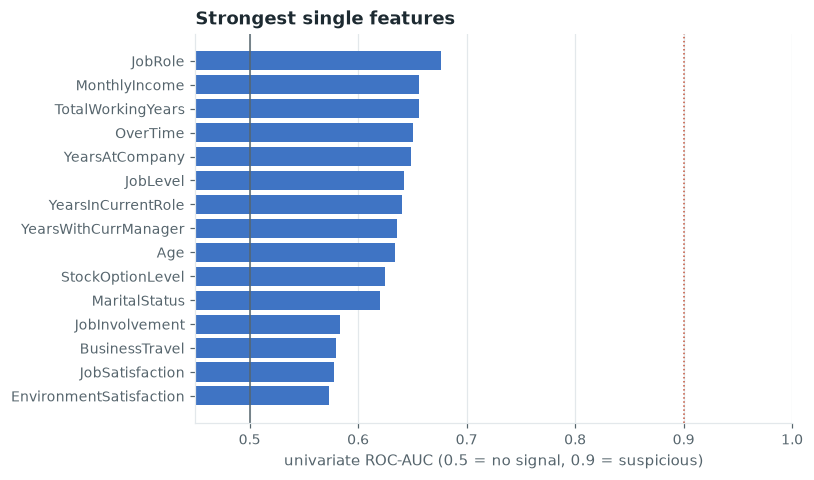

max univariate AUC: 0.676


In [11]:
ls = rep.leakage_screen.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(ls["feature"], ls["univariate_auc"], color=F.BLUE)
ax.axvline(0.5, color=F.MUTED, lw=1); ax.axvline(0.9, color=F.CLAY, lw=1, ls=":")
ax.set_xlim(0.45, 1); ax.set_xlabel("univariate ROC-AUC (0.5 = no signal, 0.9 = suspicious)")
ax.set_title("Strongest single features"); ax.grid(axis="y", visible=False); plt.show()
print("max univariate AUC:", rep.leakage_screen["univariate_auc"].max())

The strongest single feature reaches an AUC of about 0.68, far from the 0.9 alarm line, so no column behaves like a
proxy for the label. Prediction will have to come from combining many moderate signals.

## 6. What is kept for modelling

In [12]:
from talentscope.data import prepare_dataset
prepared = prepare_dataset(raw)
print("dropped:", schema.DROP_COLUMNS)
print("model features:", len(schema.MODEL_FEATURES))
pd.DataFrame({"numeric": pd.Series(schema.NUMERIC_FEATURES), "ordinal": pd.Series(schema.ORDINAL_FEATURES),
              "nominal": pd.Series(schema.NOMINAL_FEATURES)}).fillna("")

dropped: ['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']
model features: 30


,numeric,ordinal,nominal
0,Age,Education,BusinessTravel
1,DailyRate,EnvironmentSatisfaction,Department
2,DistanceFromHome,JobInvolvement,EducationField
3,HourlyRate,JobLevel,Gender
4,MonthlyIncome,JobSatisfaction,JobRole
5,MonthlyRate,PerformanceRating,MaritalStatus
6,NumCompaniesWorked,RelationshipSatisfaction,OverTime
7,PercentSalaryHike,StockOptionLevel,
8,TotalWorkingYears,WorkLifeBalance,
9,TrainingTimesLastYear,,


## Summary

| Check | Result |
|---|---|
| Rows × columns | 1,470 × 35, as documented |
| Target | 237 left (16.1%), 1,233 stayed |
| Missing / duplicates | none / none |
| Dropped | `EmployeeNumber` (identifier), `EmployeeCount`, `Over18`, `StandardHours` (constants) |
| Leakage | no single feature above 0.68 AUC |
| Watch-outs | small positive class; correlated pay, level and tenure features; `PerformanceRating` has 2 levels |

**Limitations.** 1,470 synthetic rows is a small sample. A held-out set of 20% contains only about 47 leavers, so every
held-out metric will carry a wide confidence interval. Notebook 06 quantifies how wide.